# Build a quantum ghost in Qiskit

This notebook builds the ghost from [Ghost Walk](README.md) step by step: a discrete-time quantum walk on a ring of rooms, a flashlight that is a real quantum measurement, the trick that made the walk small enough for an IBM chip, and what the chip actually did.

1. Registers and the start state
2. One walk step
3. Quantum ghost against a coin-flipping ghost
4. How fast the ghost spreads
5. The flashlight: a measurement through a sensor qubit
6. Fitting the step on a real chip
7. The ghost on ibm_kingston
8. Run it yourself

Everything runs locally in about a minute. No IBM account is needed: section 7 reads the saved results in `hardware/`. The walk itself lives in [`quantum_walk.py`](quantum_walk.py); more background in [docs/how-it-works.md](docs/how-it-works.md).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeTorino

from quantum_walk import classical_probs, ghost_walk, ideal_probs, start_room, start_state, walk_step

# the game's colours
QUANTUM, CLASSICAL, CHIP, GREY = "#6f86ff", "#e07133", "#21a88a", "#8a8a8a"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e8e8", "grid.linewidth": 0.8,
    "axes.edgecolor": "#9a9a9a", "xtick.color": "#555555", "ytick.color": "#555555",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": "#444444",
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})


def room_bars(ax, series, title):
    """Grouped bars per room. series: list of (label, probabilities, colour)."""
    rooms = len(series[0][1])
    width = 0.8 / len(series)
    x = np.arange(rooms)
    for i, (label, p, colour) in enumerate(series):
        ax.bar(x + (i - (len(series) - 1) / 2) * width, p, width, label=label, color=colour,
               edgecolor="white", linewidth=1.2)
    ax.set_xticks(x, [str(k + 1) for k in x])
    ax.set_xlabel("room")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)


def pct(v):
    """Percent rounded half up, as the game shows it (0.125 -> 13%)."""
    return f"{int(v * 100 + 0.5 + 1e-6)}%"


def show(p, label=""):
    """Print the rooms a distribution occupies, 1-based."""
    print(label + "  ".join(f"room {k + 1}: {pct(v)}" for k, v in enumerate(p) if v > 1e-9))

## 1. Registers and the start state

| Qubits | Role |
|---|---|
| 0–3 | room index, least significant bit first (16 rooms; index k is room k + 1) |
| 4 | coin: 0 = step left, 1 = step right |
| 5 | flashlight sensor, added in section 5 |

The ghost starts in room 8 (index 7 = `0111`) with the coin in (|0⟩ + i|1⟩)/√2. The phase i keeps the walk symmetric: a Hadamard walk started with a plain |0⟩ or |1⟩ coin drifts to one side.

In [2]:
qc = start_state(4)
print(qc.draw())
show(Statevector(qc).probabilities(qargs=range(4)), "start: ")

     ┌───┐     
q_0: ┤ X ├─────
     ├───┤     
q_1: ┤ X ├─────
     ├───┤     
q_2: ┤ X ├─────
     └───┘     
q_3: ──────────
     ┌───┐┌───┐
q_4: ┤ H ├┤ S ├
     └───┘└───┘
start: room 8: 100%


## 2. One walk step

A step is a Hadamard on the coin, then a shift: coin 0 moves the ghost one room left, coin 1 one room right. The shift is written as "everyone −1, then +2 if the coin is 1" (section 6 explains why). The adder wraps from room 16 to room 1, so the corridor loops for free.

In [3]:
print(walk_step(4).draw(fold=-1))

     ┌───┐               ┌───┐┌───┐          
q_0: ┤ X ├──■────■────■──┤ X ├┤ X ├──────────
     ├───┤  │    │  ┌─┴─┐├───┤└───┘     ┌───┐
q_1: ┤ X ├──■────■──┤ X ├┤ X ├──■────■──┤ X ├
     ├───┤  │  ┌─┴─┐├───┤└───┘  │  ┌─┴─┐└─┬─┘
q_2: ┤ X ├──■──┤ X ├┤ X ├───────■──┤ X ├──┼──
     ├───┤┌─┴─┐├───┤└───┘     ┌─┴─┐└─┬─┘  │  
q_3: ┤ X ├┤ X ├┤ X ├──────────┤ X ├──┼────┼──
     ├───┤└───┘└───┘          └─┬─┘  │    │  
q_4: ┤ H ├──────────────────────■────■────■──
     └───┘                                   


## 3. Quantum ghost against a coin-flipping ghost

The coin-flipping ghost picks left or right at random each step: p′ₖ = (pₖ₋₁ + pₖ₊₁)/2. For three steps the two ghosts are identical. At step four the routes back to the start carry opposite signs and cancel: the quantum ghost avoids the middle and splits in two.

step 1 quantum:   room 7: 50%  room 9: 50%
step 1 coin-flip: room 7: 50%  room 9: 50%

step 2 quantum:   room 6: 25%  room 8: 50%  room 10: 25%
step 2 coin-flip: room 6: 25%  room 8: 50%  room 10: 25%

step 3 quantum:   room 5: 13%  room 7: 38%  room 9: 38%  room 11: 13%
step 3 coin-flip: room 5: 13%  room 7: 38%  room 9: 38%  room 11: 13%

step 4 quantum:   room 4: 6%  room 6: 38%  room 8: 13%  room 10: 38%  room 12: 6%
step 4 coin-flip: room 4: 6%  room 6: 25%  room 8: 38%  room 10: 25%  room 12: 6%



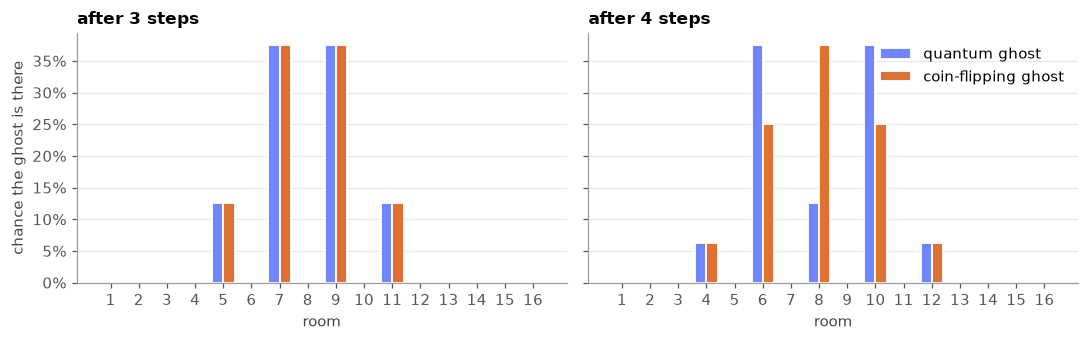

In [4]:
for t in range(1, 5):
    show(ideal_probs(t), f"step {t} quantum:   ")
    show(classical_probs(t), f"step {t} coin-flip: ")
    print()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, t in zip(axes, (3, 4)):
    room_bars(ax, [("quantum ghost", ideal_probs(t), QUANTUM), ("coin-flipping ghost", classical_probs(t), CLASSICAL)],
              f"after {t} steps")
axes[0].set_ylabel("chance the ghost is there")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. How fast the ghost spreads

On a 64-room ring (6 room qubits, so 30 steps never wrap around), the quantum ghost's spread grows in proportion to the number of steps, the coin-flipping ghost's only to its square root.

quantum spread after 30 steps: 16.3 rooms = 0.542 x steps (theory 0.541)
coin-flip spread after 30 steps: 5.5 rooms = sqrt(steps)
largest drift of the mean: 2.6e-14 rooms (symmetric start)


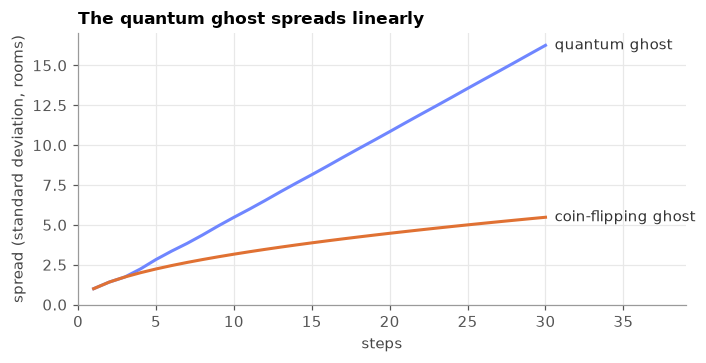

In [5]:
n = 6
x = np.arange(2**n) - start_room(n)   # position relative to the start room
state, step = Statevector(start_state(n)), walk_step(n)
steps, sd_quantum, mean = range(1, 31), [], []
for t in steps:
    state = state.evolve(step)
    p = state.probabilities(qargs=range(n))
    mean.append((p * x).sum())
    sd_quantum.append(np.sqrt((p * x**2).sum() - mean[-1] ** 2))
sd_classical = np.sqrt(np.array(steps))

print(f"quantum spread after 30 steps: {sd_quantum[-1]:.1f} rooms = {sd_quantum[-1] / 30:.3f} x steps "
      f"(theory {np.sqrt(1 - 1 / np.sqrt(2)):.3f})")
print(f"coin-flip spread after 30 steps: {sd_classical[-1]:.1f} rooms = sqrt(steps)")
print(f"largest drift of the mean: {max(abs(m) for m in mean):.1e} rooms (symmetric start)")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(steps, sd_quantum, color=QUANTUM)
ax.plot(steps, sd_classical, color=CLASSICAL)
ax.annotate("quantum ghost", (30, sd_quantum[-1]), xytext=(6, 0), textcoords="offset points", va="center", color="#333333")
ax.annotate("coin-flipping ghost", (30, sd_classical[-1]), xytext=(6, 0), textcoords="offset points", va="center", color="#333333")
ax.set_xlim(0, 39)
ax.set_ylim(0, None)
ax.set_xlabel("steps")
ax.set_ylabel("spread (standard deviation, rooms)")
ax.set_title("The quantum ghost spreads linearly", loc="left")
plt.tight_layout()
plt.show()

## 5. The flashlight: a measurement through a sensor qubit

A flashlight in room r asks one yes/no question. A sensor qubit flips only if the ghost is in room r: X gates turn the room's `0` bits into `1`s, a multi-controlled X fires on `1111`, and the X gates are undone. Measuring only the sensor answers yes or no and reveals nothing else about where the ghost is.

After a miss the sensor is back in |0⟩, so it can be reused on the next turn.

In [6]:
def flashlight_circuit(room, n_room=4):
    sensor = n_room + 1
    qc = QuantumCircuit(n_room + 2, name=f"flashlight {room + 1}")
    zeros = [i for i in range(n_room) if not (room >> i) & 1]
    if zeros:
        qc.x(zeros)
    qc.mcx(list(range(n_room)), sensor)  # sensor flips only if the ghost is in `room`
    if zeros:
        qc.x(zeros)
    return qc


def flashlight(state, room, n_room=4, seed=None):
    """Shine a flashlight into `room` (0-based). Returns (caught, state after the measurement)."""
    state = state.evolve(flashlight_circuit(room, n_room))
    if seed is not None:
        state.seed(seed)
    outcome, state = state.measure([n_room + 1])
    return outcome == "1", state


print(flashlight_circuit(6).draw())

     ┌───┐     ┌───┐
q_0: ┤ X ├──■──┤ X ├
     └───┘  │  └───┘
q_1: ───────■───────
            │       
q_2: ───────■───────
     ┌───┐  │  ┌───┐
q_3: ┤ X ├──■──┤ X ├
     └───┘  │  └───┘
q_4: ───────┼───────
          ┌─┴─┐     
q_5: ─────┤ X ├─────
          └───┘     


The game starts after three warm-up steps. Shine the flashlight into room 7, which holds 38 % of the ghost. The seed is fixed so this run misses; change it to see a catch.

In [7]:
ghost = Statevector(ghost_walk(3, measure=False)).expand(Statevector.from_label("0"))  # sensor = qubit 5
before = ghost.probabilities(qargs=range(4))
caught, after = flashlight(ghost, room=6, seed=1)

print("caught" if caught else "miss")
show(before, "before: ")
show(after.probabilities(qargs=range(4)), "after:  ")
print(f"sensor after the miss: P(0) = {after.probabilities([5])[0]:.3f}")

# The same thing written as a projector: zero room 7's amplitudes, renormalise.
amps = Statevector(ghost_walk(3, measure=False)).data.reshape(2, 16)   # [coin, room]
expected = amps.copy()
expected[:, 6] = 0
expected /= np.linalg.norm(expected)
print("sensor circuit == (I - P_r)|psi> / norm:", np.allclose(after.data[:32].reshape(2, 16), expected))

miss
before: room 5: 13%  room 7: 38%  room 9: 38%  room 11: 13%
after:  room 5: 20%  room 9: 60%  room 11: 20%
sensor after the miss: P(0) = 1.000
sensor circuit == (I - P_r)|psi> / norm: True


A miss reshapes the chances like a classical Bayesian update. The difference shows on the next step: the remaining amplitudes keep their signs, so the quantum ghost keeps interfering. Below, the quantum ghost one step after the miss against a coin-flipping ghost that starts from exactly the same chances.

next step, quantum:          room 4: 10%  room 6: 10%  room 8: 10%  room 10: 60%  room 12: 10%
next step, coin-flip, same start: room 4: 10%  room 6: 10%  room 8: 30%  room 10: 40%  room 12: 10%


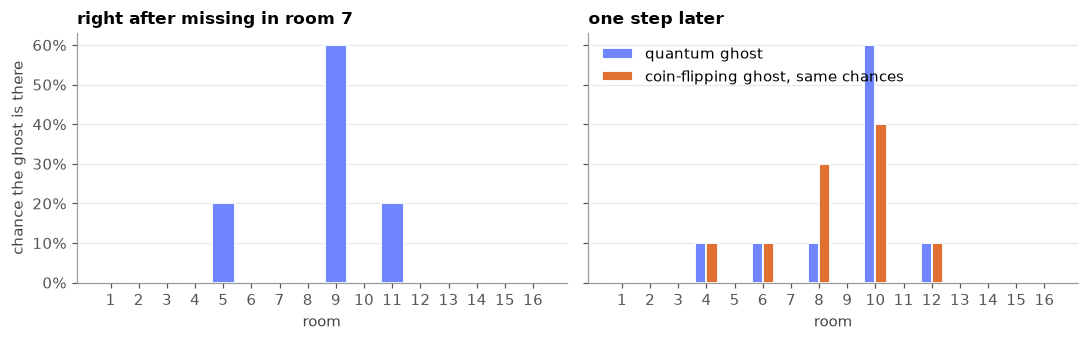

In [8]:
p_miss = after.probabilities(qargs=range(4))
q_next = after.evolve(walk_step(4), qargs=range(5)).probabilities(qargs=range(4))
c_next = (np.roll(p_miss, 1) + np.roll(p_miss, -1)) / 2

show(q_next, "next step, quantum:          ")
show(c_next, "next step, coin-flip, same start: ")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
room_bars(axes[0], [("quantum ghost", p_miss, QUANTUM)], "right after missing in room 7")
room_bars(axes[1], [("quantum ghost", q_next, QUANTUM), ("coin-flipping ghost, same chances", c_next, CLASSICAL)],
          "one step later")
axes[0].set_ylabel("chance the ghost is there")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. Fitting the step on a real chip

The textbook shift is a controlled +1 and a controlled −1 on the room register. IBM chips only have two-qubit gates between neighbouring qubits, so those multi-controlled gates expand into hundreds of two-qubit gates.

`walk_step` writes the shift as "everyone −1 (not controlled), then +2 if the coin is 1". +2 never touches the lowest room bit, so the only controlled adder is one qubit smaller. First check that both are exactly the same unitary, then count two-qubit gates after transpiling for an IBM Heron chip (FakeTorino, a local model of `ibm_torino`).

In [9]:
def increment(n):
    qc = QuantumCircuit(n, name="+1")
    for i in reversed(range(1, n)):
        qc.mcx(list(range(i)), i)
    qc.x(0)
    return qc


def textbook_step(n_room):
    qc = QuantumCircuit(n_room + 1)
    room, coin = list(range(n_room)), n_room
    qc.h(coin)
    inc = increment(n_room).to_gate()
    qc.append(inc.control(1), [coin] + room)            # coin = 1 -> room + 1
    qc.x(coin)
    qc.append(inc.inverse().control(1), [coin] + room)  # coin = 0 -> room - 1
    qc.x(coin)
    return qc


pm = generate_preset_pass_manager(backend=FakeTorino(), optimization_level=3, seed_transpiler=7)
two_qubit = lambda qc: sum(1 for inst in qc.data if inst.operation.num_qubits == 2)

for n in (3, 4):
    same = Operator(walk_step(n)).equiv(Operator(textbook_step(n)))
    print(f"{2**n:>2} rooms: same unitary = {same}, two-qubit gates per step: "
          f"textbook {two_qubit(pm.run(textbook_step(n)))}, ours {two_qubit(pm.run(walk_step(n)))}")

 8 rooms: same unitary = True, two-qubit gates per step: textbook 141, ours 16
16 rooms: same unitary = True, two-qubit gates per step: textbook 458, ours 60


## 7. The ghost on ibm_kingston

`run_on_ibm.py` sent the walk for both ring sizes and 1–8 steps to `ibm_kingston` in one job, 2000 shots per circuit, and saved every shot. "Distance" is the total variation distance between two distributions: the share of the ghost you would have to move to turn one picture into the other (0 = identical, 1 = nothing in common).

job dbdqmq7gdj9s73fko830 on ibm_kingston, 2000 shots per circuit, QPU time 11 s
8 rooms, 5 steps, quantum:   room 1: 38%  room 3: 13%  room 5: 13%  room 7: 38%
8 rooms, 5 steps, coin-flip: room 1: 19%  room 3: 31%  room 5: 31%  room 7: 19%
8 rooms, 5 steps, chip:      room 1: 32%  room 2: 2%  room 3: 15%  room 4: 1%  room 5: 11%  room 6: 2%  room 7: 34%  room 8: 3%
distance from quantum 0.10, from coin-flip 0.37, physical qubits [75, 55, 59, 54]


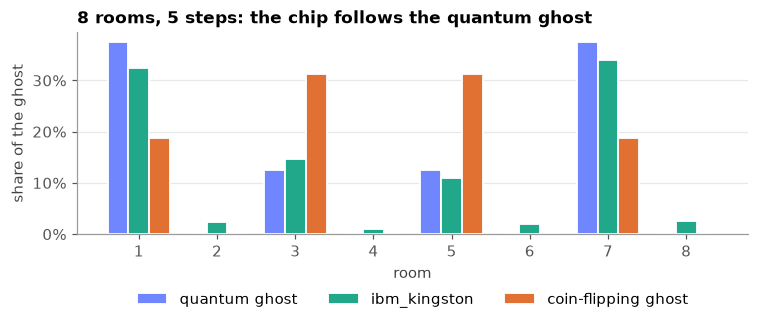

In [10]:
run = json.loads(Path("hardware/results.json").read_text())
get = lambda rooms, steps: next(c for c in run["circuits"] if c["rooms"] == rooms and c["steps"] == steps)
metrics = run["metrics"]
print(f"job {run['job_id']} on {run['backend']}, {run['shots']} shots per circuit, "
      f"QPU time {metrics['usage']['qpu_charge_time_seconds']} s")

c = get(8, 5)
show(c["ideal_probs"], "8 rooms, 5 steps, quantum:   ")
show(c["classical_probs"], "8 rooms, 5 steps, coin-flip: ")
print("8 rooms, 5 steps, chip:      " + "  ".join(f"room {k + 1}: {pct(v)}" for k, v in enumerate(c["real_probs"])))
print(f"distance from quantum {c['tvd_ideal']:.2f}, from coin-flip {c['tvd_classical']:.2f}, physical qubits {c['physical_qubits']}")

fig, ax = plt.subplots(figsize=(7, 3.2))
room_bars(ax, [("quantum ghost", c["ideal_probs"], QUANTUM), ("ibm_kingston", c["real_probs"], CHIP),
               ("coin-flipping ghost", c["classical_probs"], CLASSICAL)],
          "8 rooms, 5 steps: the chip follows the quantum ghost")
ax.set_ylabel("share of the ghost")
ax.legend(loc="upper center", ncols=3, bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.show()

Step by step. For three steps the quantum and the coin-flipping ghost are the same, so both distances coincide. The 8-room ring follows the quantum ghost from step 4 on (steps 6 and 7 ran on weaker qubits, see [docs/real-chip.md](docs/real-chip.md)). The 16-room ring needs about four times more gates per step and by step 3 is closer to "evenly everywhere" than to the quantum ghost.

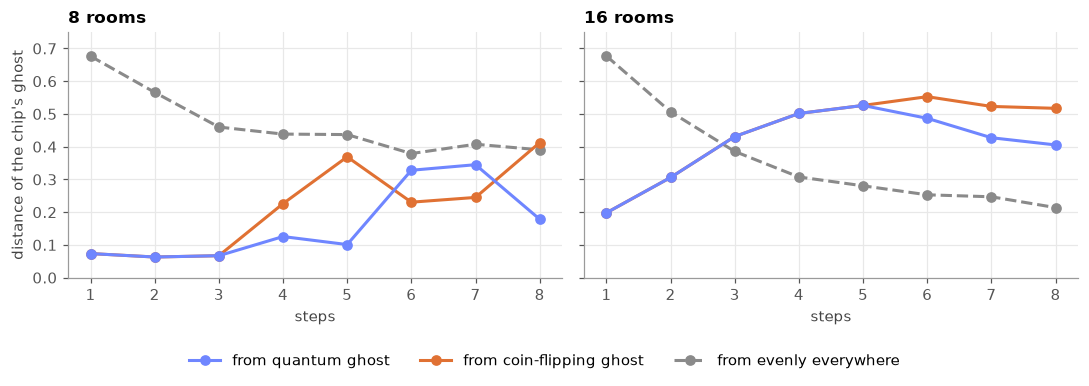

steps                       1     2     3     4     5     6     7     8
 8 rooms from quantum    0.07  0.06  0.07  0.13  0.10  0.33  0.34  0.18
 8 rooms from coin-flip  0.07  0.06  0.07  0.23  0.37  0.23  0.24  0.41
 8 rooms from uniform    0.68  0.57  0.46  0.44  0.44  0.38  0.41  0.39
16 rooms from quantum    0.20  0.31  0.43  0.50  0.53  0.49  0.43  0.41
16 rooms from coin-flip  0.20  0.31  0.43  0.50  0.53  0.55  0.52  0.52
16 rooms from uniform    0.68  0.51  0.39  0.31  0.28  0.25  0.25  0.21


In [11]:
steps = range(1, 9)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, rooms in zip(axes, (8, 16)):
    # quantum drawn last: where the two predictions coincide (steps 1-3) it stays visible
    lines = [("from evenly everywhere", "tvd_uniform", GREY, "--"), ("from coin-flipping ghost", "tvd_classical", CLASSICAL, "-"),
             ("from quantum ghost", "tvd_ideal", QUANTUM, "-")]
    for label, key, colour, style in lines:
        ax.plot(steps, [get(rooms, s)[key] for s in steps], style, color=colour, marker="o", label=label)
    ax.set_title(f"{rooms} rooms", loc="left")
    ax.set_xlabel("steps")
    ax.set_xticks(list(steps))
axes[0].set_ylabel("distance of the chip's ghost")
axes[0].set_ylim(0, 0.75)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="lower center", ncols=3, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

print("steps                  " + "".join(f"{s:>6}" for s in steps))
for rooms in (8, 16):
    for label, key in (("from quantum", "tvd_ideal"), ("from coin-flip", "tvd_classical"), ("from uniform", "tvd_uniform")):
        print(f"{rooms:>2} rooms {label:<14}" + "".join(f"{get(rooms, s)[key]:>6.2f}" for s in steps))

Noise does not turn the ghost classical. A perfect ghost, quantum or coin-flipping, moves one room per step and so is never in a room of the wrong parity. Every shot there is noise: the ghost leaking into every room.

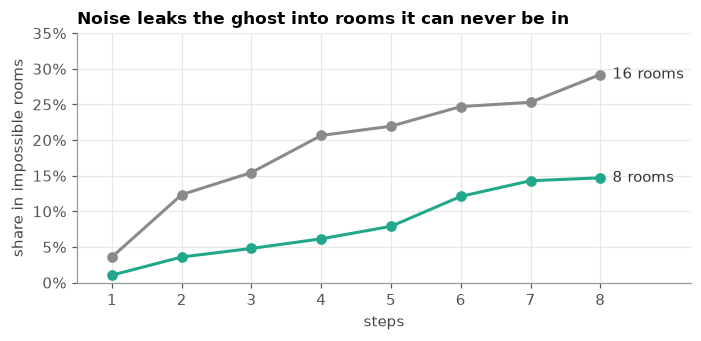

leak, 8 rooms: 1%, 4%, 5%, 6%, 8%, 12%, 14%, 15%
leak, 16 rooms: 4%, 12%, 15%, 21%, 22%, 25%, 25%, 29%


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for rooms, colour in ((16, GREY), (8, CHIP)):
    leak = [get(rooms, s)["wrong_parity"] for s in steps]
    ax.plot(steps, leak, color=colour, marker="o")
    ax.annotate(f"{rooms} rooms", (8, leak[-1]), xytext=(8, 0), textcoords="offset points", va="center", color="#333333")
ax.set_xlim(0.5, 9.3)
ax.set_xticks(list(steps))
ax.set_ylim(0, 0.35)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("steps")
ax.set_ylabel("share in impossible rooms")
ax.set_title("Noise leaks the ghost into rooms it can never be in", loc="left")
plt.tight_layout()
plt.show()
print("leak, 8 rooms: " + ", ".join(f"{get(8, s)['wrong_parity']:.0%}" for s in steps))
print("leak, 16 rooms: " + ", ".join(f"{get(16, s)['wrong_parity']:.0%}" for s in steps))

## 8. Run it yourself

The whole hardware pipeline runs locally on a noisy simulator, no account needed:

```bash
python run_on_ibm.py submit --fake
```

With an [IBM Quantum Platform](https://quantum.cloud.ibm.com) account (the free Open Plan is enough; one job is about 10 s of QPU time):

```bash
python run_on_ibm.py submit --backend ibm_kingston --dry-run   # plan only, nothing sent
python run_on_ibm.py submit --backend ibm_kingston --tag mine  # one job, id saved first
python run_on_ibm.py fetch --tag mine --wait                   # results in hardware/results_mine.json
```

Ideas to take further: a bigger ring with a cheaper adder, a 2D mansion with two coin qubits, or a ghost player who chooses the coin each turn to steer the interference.